<a href="https://colab.research.google.com/github/fahadahmad84-design/Quantum-Computing-Labs/blob/main/notebooks/Week_08_QC_M34099_Student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 8 Laboratory: Variational Circuits and Simple Quantum Machine Learning

[![View in GitHub](https://img.shields.io/badge/View%20in-GitHub-black?logo=github)](https://github.com/fahadahmad84-design/Quantum-Computing-Labs/blob/main/notebooks/Week_08_QC_M34099_Student.ipynb)

**M34099 Quantum Computing: Level 7 (2026/27)**

This laboratory contains three basic tasks:

1. Build a one-qubit parameterised circuit;
2. Compare exact and finite-shot expectation values and find a minimum; and
3. Use the circuit output as a simple classifier.

The examples use one qubit so that every step can be checked by hand.

> **Saving your work:** In Colab, select **File > Save a copy in Drive** before editing.


## Set up Google Colab

Run the installation cell once. If Colab requests a restart, select **Runtime > Restart session**, then continue from the imports cell.


In [1]:
# Install Qiskit, the Aer simulator, IBM Runtime, and drawing support.
%pip install -q "qiskit[visualization]" qiskit-aer qiskit-ibm-runtime pylatexenc


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 3.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 3.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.


In [2]:
# Import NumPy for angles, arrays, and simple calculations.
import numpy as np
# Import the Qiskit circuit and transpiler tools.
from qiskit import QuantumCircuit, transpile
# Import the local ideal simulator.
from qiskit_aer import AerSimulator
# Import the histogram plotting function.
from qiskit.visualization import plot_histogram

# Set the number of repeated measurements.
SHOTS = 1024
# Set a fixed seed for repeatable simulator results.
SEED = 34099
# Create the ideal simulator.
simulator = AerSimulator()
# Confirm that the setup is ready.
print("Setup complete.")


Setup complete.


## Task 1: Build a parameterised one-qubit circuit

The circuit starts in $|0\rangle$ and applies an $R_Y(\theta)$ gate:

$$
R_Y(\theta)|0\rangle
=
\cos(\theta/2)|0\rangle
+
\sin(\theta/2)|1\rangle.
$$

Changing $\theta$ changes the probabilities of measuring 0 and 1.


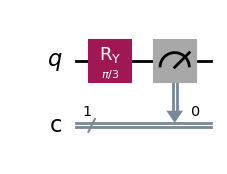

P(0) = 0.7500000000000001
P(1) = 0.24999999999999994
Exact <Z> = 0.5000000000000002


In [3]:
# Create a function that builds a measured RY circuit.
def make_ry_circuit(theta):
    # Create one qubit and one classical bit.
    circuit = QuantumCircuit(1, 1)
    # Rotate the qubit by the selected angle.
    circuit.ry(theta, 0)
    # Measure the qubit in the Z basis.
    circuit.measure(0, 0)
    # Return the completed circuit.
    return circuit

# Select pi divided by three as an example angle.
example_theta = np.pi / 3
# Build the example circuit.
example_circuit = make_ry_circuit(example_theta)
# Draw the circuit.
display(example_circuit.draw("mpl"))

# Calculate the exact probability of measuring zero.
probability_zero = np.cos(example_theta / 2) ** 2
# Calculate the exact probability of measuring one.
probability_one = np.sin(example_theta / 2) ** 2
# Calculate the exact Z expectation value.
exact_expectation = probability_zero - probability_one

# Display the exact probabilities.
print("P(0) =", probability_zero)
# Display the exact probability of one.
print("P(1) =", probability_one)
# Display the exact Z expectation value.
print("Exact <Z> =", exact_expectation)


### Result

For $\theta=\pi/3$:

$$P(0)=3/4,\qquad P(1)=1/4,$$

so

$$\langle Z\rangle=P(0)-P(1)=1/2.$$

The parameter $\theta$ controls the state prepared by the circuit.


## Task 2: Compare exact and finite-shot expectation values

The simulator measures the circuit 1024 times. The measured expectation value is

$$
\langle Z\rangle_{\text{shots}}
=
\frac{n_0-n_1}{1024}.
$$

The finite-shot value should be close to the exact result $\cos(\theta)$, but it may not be identical because measurements are sampled.


theta = 0.00, exact = 1.000, measured = 1.000
theta = 1.05, exact = 0.500, measured = 0.404
theta = 1.57, exact = 0.000, measured = -0.055
theta = 3.14, exact = -1.000, measured = -1.000


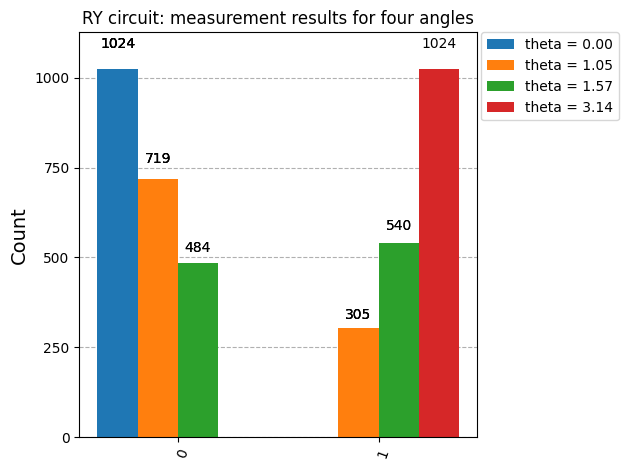

In [4]:
# Create a function that estimates the Z expectation value with measurements.
def measure_z_expectation(theta, run_seed=SEED):
    # Build the measured circuit for the selected angle.
    circuit = make_ry_circuit(theta)
    # Convert the circuit for the simulator.
    compiled = transpile(circuit, simulator, seed_transpiler=SEED)
    # Run the circuit with a fixed number of shots.
    job = simulator.run(compiled, shots=SHOTS, seed_simulator=run_seed)
    # Collect the measurement counts.
    counts = job.result().get_counts()
    # Read the number of zero outcomes.
    zero_count = counts.get("0", 0)
    # Read the number of one outcomes.
    one_count = counts.get("1", 0)
    # Calculate the measured Z expectation value.
    expectation = (zero_count - one_count) / SHOTS
    # Return the expectation value and counts.
    return expectation, counts

# Store four clear test angles.
test_angles = [0, np.pi / 3, np.pi / 2, np.pi]
# Create an empty dictionary for the histograms.
angle_counts = {}

# Test each selected angle.
for theta in test_angles:
    # Calculate the exact expectation value.
    exact_value = np.cos(theta)
    # Estimate the expectation value from measurements.
    measured_value, counts = measure_z_expectation(theta)
    # Store the measurement counts.
    angle_counts[f"theta = {theta:.2f}"] = counts
    # Display the exact and measured values.
    print(f"theta = {theta:.2f}, exact = {exact_value:.3f}, measured = {measured_value:.3f}")

# Compare the four measurement distributions.
display(plot_histogram(
    list(angle_counts.values()),
    legend=list(angle_counts.keys()),
    title="RY circuit: measurement results for four angles",
))


### Find the lowest cost

Use the expectation value as the cost:

$$C(\theta)=\langle Z\rangle=\cos(\theta).$$

A simple classical search tests several angles and selects the angle with the lowest cost. This is a basic version of the hybrid optimisation loop.


In [5]:
# Create 25 candidate angles between zero and two pi.
candidate_angles = np.linspace(0, 2 * np.pi, 25)
# Create an empty list for the exact costs.
exact_costs = []

# Test every candidate angle.
for theta in candidate_angles:
    # Calculate the exact cost for this angle.
    cost = np.cos(theta)
    # Store the cost.
    exact_costs.append(cost)

# Find the position of the smallest cost.
best_index = int(np.argmin(exact_costs))
# Read the best angle.
best_theta = candidate_angles[best_index]
# Read the smallest exact cost.
best_exact_cost = exact_costs[best_index]
# Estimate the cost at the best angle with finite shots.
best_measured_cost, best_counts = measure_z_expectation(best_theta)

# Display the best angle.
print("Best theta =", best_theta)
# Display the exact minimum cost.
print("Exact minimum cost =", best_exact_cost)
# Display the measured cost at the same angle.
print("Measured cost =", best_measured_cost)
# Display the measurement counts at the best angle.
print("Counts =", best_counts)


Best theta = 3.141592653589793
Exact minimum cost = -1.0
Measured cost = -1.0
Counts = {'1': 1024}


### Result

The exact minimum occurs at

$$\theta=\pi,$$

where

$$C(\pi)=\cos(\pi)=-1.$$

The finite-shot estimate should be close to $-1$. A lower measured cost supports optimisation progress. Comparison with the known exact minimum checks whether the correct solution was found.


## Task 3: Use the circuit as a simple classifier

Use one feature $x$ and one trainable parameter $\theta$:

$$
R_Y(\theta)R_Y(x)|0\rangle
=
R_Y(x+\theta)|0\rangle.
$$

The model output is

$$\langle Z\rangle=\cos(x+\theta).$$

Use the rule:

- class 0 when $\langle Z\rangle\geq0$;
- class 1 when $\langle Z\rangle<0$.

The code tests a small set of parameter values and keeps the value with the highest training accuracy.


In [6]:
# Store four simple training features.
train_x = np.array([0.2, 0.8, 1.4, 2.2])
# Store the correct training labels.
train_y = np.array([0, 0, 1, 1])
# Store two separate test features.
test_x = np.array([0.5, 1.8])
# Store the correct test labels.
test_y = np.array([0, 1])
# Create simple candidate values for the trainable parameter.
candidate_thetas = np.linspace(0, 1.0, 11)
# Start with an empty best parameter.
best_classifier_theta = None
# Start with an accuracy below every possible result.
best_training_accuracy = -1.0

# Test each candidate parameter.
for theta in candidate_thetas:
    # Calculate the model expectation values for the training features.
    train_expectations = np.cos(train_x + theta)
    # Convert negative expectations into class one.
    train_predictions = (train_expectations < 0).astype(int)
    # Calculate the training accuracy.
    training_accuracy = np.mean(train_predictions == train_y)
    # Keep this parameter when it improves the accuracy.
    if training_accuracy > best_training_accuracy:
        # Store the improved training accuracy.
        best_training_accuracy = training_accuracy
        # Store the corresponding parameter.
        best_classifier_theta = theta

# Calculate expectations for the separate test features.
test_expectations = np.cos(test_x + best_classifier_theta)
# Convert the test expectations into class predictions.
test_predictions = (test_expectations < 0).astype(int)
# Calculate the test accuracy.
test_accuracy = np.mean(test_predictions == test_y)

# Display the selected parameter.
print("Selected theta =", best_classifier_theta)
# Display the training accuracy.
print("Training accuracy =", best_training_accuracy)
# Display each test feature, prediction, and correct label.
print("Test results =", list(zip(test_x, test_predictions, test_y)))
# Display the test accuracy.
print("Test accuracy =", test_accuracy)


Selected theta = 0.2
Training accuracy = 1.0
Test results = [(np.float64(0.5), np.int64(0), np.int64(0)), (np.float64(1.8), np.int64(1), np.int64(1))]
Test accuracy = 1.0


### Result

The parameter $\theta$ moves the classifier's decision boundary. The training data selects a useful value, and the separate test data checks whether the rule also works on unseen examples.

This small example demonstrates the QML workflow. It does not demonstrate quantum advantage. A serious comparison would require more data, repeated splits, uncertainty reporting, a classical baseline and complete resource reporting.


## Optional: Compare one circuit on IBM quantum hardware

Run this section only after your tutor confirms that IBM Quantum Classroom access is ready. The circuit with $\theta=\pi/3$ is used so the ideal simulator and hardware counts can be compared directly.

- Keep `RUN_ON_REAL_HARDWARE = False` until access is ready.
- Enter your API key and classroom CRN only through the hidden prompts.
- Never save credentials in the notebook, Google Drive, Moodle or GitHub.


In [7]:
# Keep real-hardware execution disabled until access is ready.
RUN_ON_REAL_HARDWARE = False
# Display the current hardware setting.
print("Real-hardware execution enabled:", RUN_ON_REAL_HARDWARE)


Real-hardware execution enabled: False


In [8]:
# Continue only when real-hardware execution is enabled.
if RUN_ON_REAL_HARDWARE:
    # Import secure hidden-input support.
    from getpass import getpass
    # Import the IBM Quantum Runtime connection.
    from qiskit_ibm_runtime import QiskitRuntimeService
    # Import the IBM Runtime Sampler interface.
    from qiskit_ibm_runtime import SamplerV2
    # Import the device-aware circuit pass manager.
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

    # Connect only once during the current Colab session.
    if "ibm_service" not in globals():
        # Request the API key without displaying it.
        ibm_api_key = getpass("Enter your personal IBM Cloud API key: ")
        # Request the classroom CRN without displaying it.
        classroom_crn = getpass("Enter the classroom instance CRN: ")
        # Connect to the classroom instance.
        ibm_service = QiskitRuntimeService(
            channel="ibm_quantum_platform",
            token=ibm_api_key,
            instance=classroom_crn,
        )
        # Remove the plaintext credential variables.
        del ibm_api_key, classroom_crn

    # Select an operational quantum computer with a short queue.
    backend = ibm_service.least_busy(operational=True, simulator=False)
    # Display the selected device.
    print("Selected backend:", backend.name)
    # Create a pass manager for the selected device.
    pass_manager = generate_preset_pass_manager(backend=backend, optimization_level=1)
    # Convert the example circuit for the real device.
    hardware_circuit = pass_manager.run(example_circuit)
    # Create the Runtime Sampler.
    sampler = SamplerV2(mode=backend)
    # Submit the circuit as one hardware job.
    hardware_job = sampler.run([hardware_circuit], shots=SHOTS)
    # Display the job identifier.
    print("Job ID:", hardware_job.job_id())
    # Wait for the job and collect the result.
    hardware_result = hardware_job.result()
    # Extract ordinary measurement counts from the result.
    hardware_counts = hardware_result[0].data.c.get_counts()
    # Obtain the matching ideal simulator counts.
    ideal_expectation, ideal_counts = measure_z_expectation(example_theta)
    # Display the hardware counts.
    print("Hardware results:", hardware_counts)
    # Compare ideal and hardware measurement distributions.
    display(plot_histogram(
        [ideal_counts, hardware_counts],
        legend=["Ideal simulator", f"IBM {backend.name}"],
        title="RY circuit: simulator and hardware comparison",
    ))
# Skip the hardware job when the safety switch is off.
else:
    # Confirm that no hardware job was submitted.
    print("No hardware job submitted.")


No hardware job submitted.


### Hardware result

The simulator should produce counts close to $P(0)=0.75$ and $P(1)=0.25$. Real hardware may differ because physical qubits, gates and measurements are noisy.


## References

- IBM Quantum Learning, *Variational algorithm design*: https://quantum.cloud.ibm.com/learning/en/courses/variational-algorithm-design
- IBM Quantum Documentation, *Run jobs with Qiskit Runtime*: https://quantum.cloud.ibm.com/docs/guides/run-jobs
- Qiskit Aer documentation: https://qiskit.github.io/qiskit-aer/

Accessed 16 November 2026.
